# 03 — Modelo de PD: regresión logística

**Objetivo.** Estimar la probabilidad de default (PD) de octubre de 2005 con una regresión
logística sobre las variables WOE de la fase anterior, medir su capacidad de discriminación y su
calibración, y dejar el modelo listo para convertirlo en scorecard. Las decisiones están en
`docs/DECISIONS.md` (ADR-012).

Se construyen dos modelos con el mismo procedimiento:

- **el campeón**, con las candidatas de ADR-011 (sin el estado de septiembre);
- **el modelo de sensibilidad** de ADR-009, con las mismas candidatas más `STATUS_SEP`. Solo sirve
  para mostrar cuánto ganaría la predicción si el estado de septiembre fuera legítimo.

**Cómo se mide sin hacer trampa.** El procedimiento completo (binning, preselección, selección de
variables y logística) se vuelve a ajustar dentro de cada uno de los 15 folds de validación
cruzada, y se mide en las filas que ese fold no vio. Así ninguna decisión de esta fase ve las
filas con que se la evalúa. El conjunto de test se usará una sola vez, al final, con el modelo ya
congelado.

Todos los cálculos están en `creditrisk.models`; las cifras se guardan en
`reports/metrics/pd_logistic_cv.json`.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from sklearn.metrics import roc_curve

from creditrisk import plotting
from creditrisk.config import load_config
from creditrisk.data.split import load_train
from creditrisk.models.report import train_report
from creditrisk.reporting import save_metrics

plotting.apply_style()
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)

NAMES = {"champion": "campeón", "sensitivity_with_status_sep": "sensibilidad (con STATUS_SEP)"}

## 1. Ajuste y validación cruzada

`train_report` ajusta los dos modelos con todo train y los mide con validación cruzada. Los
intervalos de confianza vienen de 1,000 remuestreos bootstrap estratificados, con la semilla del
proyecto.

In [2]:
train = load_train()
report, models, oof = train_report(train, n_boot=1000)  # bootstrap seed from config
y = train["DEFAULT"]
print(f"Filas de entrenamiento: {report['n_train_rows']:,}")
print(f"Tasa de default en train: {report['train_default_rate']:.2%}")

Filas de entrenamiento: 24,000
Tasa de default en train: 22.12%


## 2. Selección de variables

Cada candidata pasa por tres filtros, en este orden:

1. **IV** de al menos 0.02 (ADR-011).
2. **Correlación** de WOE de como mucho 0.7 con una variable más fuerte (ADR-011).
3. **Logística**: con WOE = ln(no-defaults / defaults), un bin más seguro tiene WOE mayor, así que
   todo coeficiente de un modelo de PD debe ser **negativo**. Se quita primero, de a una, cualquier
   variable con signo positivo; luego, de a una, la de mayor p-valor si supera 0.05 (ADR-012).

In [3]:
STATUS = {
    "in model": "en el modelo",
    "IV below 0.02": "IV menor que 0.02",
    "logistic: wrong sign": "logística: signo incorrecto",
    "logistic: p-value above 0.05": "logística: p-valor mayor que 0.05",
}


def status_es(text):
    return STATUS.get(text, text.replace("correlated with", "correlacionada con"))


for name, model in report["models"].items():
    table = pd.DataFrame(model["selection"]).set_index("feature")
    view = pd.DataFrame({"IV": table["iv"].round(3), "resultado": table["status"].map(status_es)})
    view.index.name = "variable"
    print(f"Modelo {NAMES[name]}: {len(model['final_features'])} variables en el modelo")
    display(view)

Modelo campeón: 5 variables en el modelo


,IV,resultado
variable,,
N_DELAY_MONTHS,0.641,en el modelo
MONTHS_SINCE_DELAY,0.630,correlacionada con N_DELAY_MONTHS
STATUS_AUG,0.550,correlacionada con N_DELAY_MONTHS
MAX_DELAY,0.531,correlacionada con N_DELAY_MONTHS
PAY_RATIO_1,0.266,en el modelo
PAY_RATIO_2,0.218,logística: p-valor mayor que 0.05
PAY_RATIO_MEAN,0.210,en el modelo
PAY_RATIO_3,0.193,logística: p-valor mayor que 0.05
LIMIT_BAL,0.175,en el modelo


Modelo sensibilidad (con STATUS_SEP): 7 variables en el modelo


,IV,resultado
variable,,
STATUS_SEP,0.873,en el modelo
N_DELAY_MONTHS,0.641,en el modelo
MONTHS_SINCE_DELAY,0.630,correlacionada con N_DELAY_MONTHS
STATUS_AUG,0.550,correlacionada con N_DELAY_MONTHS
MAX_DELAY,0.531,correlacionada con N_DELAY_MONTHS
PAY_RATIO_1,0.266,logística: p-valor mayor que 0.05
PAY_RATIO_2,0.218,en el modelo
PAY_RATIO_MEAN,0.210,en el modelo
PAY_RATIO_3,0.193,en el modelo


En el campeón, la logística quitó cinco variables, en este orden: `UTIL_6`, `PAY_RATIO_5` y
`UTIL_2` por **signo incorrecto**, y `PAY_RATIO_3` y `PAY_RATIO_2` por p-valor.

- **Utilización.** Solo las dos variables de utilización que pasaron la preselección (`UTIL_6` y
  `UTIL_2`) llegaron a la logística; las demás habían salido antes por su correlación con ellas, y
  `UTIL_TREND` por IV. Por sí solas tienen el signo esperado, pero una vez que el modelo conoce el
  límite y el comportamiento de pago, sus bins más "seguros" pasan a asociarse con una PD mayor. Su
  relación con el default ya está contenida en las otras variables, y un coeficiente con el signo
  cambiado no se puede defender ante un comité de riesgo.
- **`PAY_RATIO_5`** (ratio de pago de mayo) se invierte por lo mismo: se superpone con el ratio
  promedio y con los de septiembre y junio, que ya están en el modelo.
- **`PAY_RATIO_3` y `PAY_RATIO_2`** salen por p-valor: no agregan información significativa a los
  ratios que quedan.

## 3. Coeficientes del campeón

Estimación, error estándar, p-valor e intervalo de confianza del 95% (statsmodels, máxima
verosimilitud sin penalización).

In [4]:
COLUMNS = {
    "coef": "coeficiente",
    "std_err": "error estándar",
    "z": "z",
    "p_value": "p-valor",
    "ci_low": "IC 95% inferior",
    "ci_high": "IC 95% superior",
}
for name in ["champion", "sensitivity_with_status_sep"]:
    coefs = pd.DataFrame(report["models"][name]["coefficients"]).set_index("term")
    coefs.index = coefs.index.str.replace("const", "intercepto")
    coefs.index.name = "término"
    print(f"Modelo {NAMES[name]}")
    display(coefs.rename(columns=COLUMNS).round(4))

Modelo campeón


,coeficiente,error estándar,z,p-valor,IC 95% inferior,IC 95% superior
término,,,,,,
intercepto,-1.2550,0.0169,-74.1808,0.0000,-1.2882,-1.2219
N_DELAY_MONTHS,-0.7985,0.0231,-34.5070,0.0000,-0.8439,-0.7532
PAY_RATIO_1,-0.1982,0.0375,-5.2845,0.0000,-0.2717,-0.1247
PAY_RATIO_MEAN,-0.3225,0.0444,-7.2695,0.0000,-0.4095,-0.2356
LIMIT_BAL,-0.4321,0.0421,-10.2610,0.0000,-0.5147,-0.3496
PAY_RATIO_4,-0.1241,0.0466,-2.6640,0.0077,-0.2153,-0.0328


Modelo sensibilidad (con STATUS_SEP)


,coeficiente,error estándar,z,p-valor,IC 95% inferior,IC 95% superior
término,,,,,,
intercepto,-1.2425,0.0175,-70.8617,0.0000,-1.2769,-1.2082
STATUS_SEP,-0.7442,0.0206,-36.2019,0.0000,-0.7845,-0.7039
N_DELAY_MONTHS,-0.3588,0.0286,-12.5368,0.0000,-0.4149,-0.3027
PAY_RATIO_2,-0.0909,0.0444,-2.0479,0.0406,-0.1779,-0.0039
PAY_RATIO_MEAN,-0.1442,0.0473,-3.0456,0.0023,-0.2369,-0.0514
PAY_RATIO_3,-0.1663,0.0461,-3.6122,0.0003,-0.2566,-0.0761
LIMIT_BAL,-0.4213,0.0440,-9.5769,0.0000,-0.5076,-0.3351
PAY_RATIO_4,-0.1759,0.0483,-3.6394,0.0003,-0.2707,-0.0812


**Revisión de signos.** Todos los coeficientes del campeón son negativos, como exige la convención
del WOE: más meses con atraso, un ratio de pago menor o un límite más bajo llevan a bins de WOE
negativo y, por tanto, a una PD mayor. El coeficiente más grande en valor absoluto es el de
`N_DELAY_MONTHS`, coherente con que el historial de atrasos sea la variable de mayor IV.

En el modelo de sensibilidad, el coeficiente de `N_DELAY_MONTHS` se reduce a menos de la mitad: el
estado de septiembre toma buena parte de su lugar, porque las dos describen atrasos.

Los errores estándar, p-valores e intervalos de la tabla son los habituales de statsmodels. No
tienen en cuenta que las variables y sus bins se eligieron con los mismos datos, así que son algo
optimistas (intervalos más estrechos de lo que serían si se consideraran esas elecciones).

## 4. Discriminación en validación cruzada

Las métricas se calculan sobre las predicciones fuera de fold: cada fila de train recibe una
predicción de un modelo que no la vio. Se muestran con su intervalo bootstrap (primera repetición),
el AUC de cada una de las tres repeticiones y el rango entre los 15 folds.

El intervalo bootstrap remuestrea filas y deja fijos los cinco modelos de cada fold: mide cuánto
cambiaría la métrica con otra muestra de clientes, no cuánto cambiaría si se reajustara todo. Por
eso se muestran también el AUC de cada repetición y el rango entre folds, que sí reflejan el
reajuste.

In [5]:
rows = {}
for name, model in report["models"].items():
    cv = model["cv"]
    r1 = cv["repeat_1"]
    row = {}
    for metric, label in [("auc", "AUC"), ("gini", "Gini"), ("ks", "KS"), ("pr_auc", "PR-AUC")]:
        m = r1[metric]
        row[label] = f"{m['estimate']:.3f} [{m['low']:.3f}, {m['high']:.3f}]"
    row["AUC por repetición"] = ", ".join(f"{v:.3f}" for v in cv["auc_by_repeat"].values())
    row["AUC por fold (mín-máx)"] = f"{cv['fold_auc_min']:.3f}-{cv['fold_auc_max']:.3f}"
    row["AUC en el propio train"] = f"{model['train_fit_auc']:.3f}"
    rows[NAMES[name]] = row
discrimination = pd.DataFrame(rows).T
discrimination.index.name = "modelo"
display(discrimination)

,AUC,Gini,KS,PR-AUC,AUC por repetición,AUC por fold (mín-máx),AUC en el propio train
modelo,,,,,,,
campeón,"0.718 [0.710, 0.725]","0.435 [0.420, 0.451]","0.341 [0.329, 0.357]","0.459 [0.447, 0.471]","0.718, 0.717, 0.719",0.707-0.738,0.720
sensibilidad (con STATUS_SEP),"0.761 [0.753, 0.768]","0.522 [0.506, 0.536]","0.412 [0.400, 0.427]","0.529 [0.517, 0.543]","0.761, 0.759, 0.761",0.744-0.777,0.764


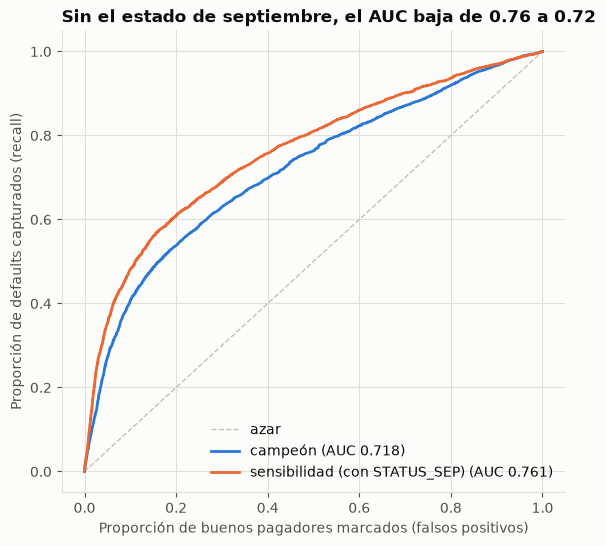

In [6]:
fig, ax = plt.subplots(figsize=(6.5, 6))
colours = {"champion": plotting.BLUE, "sensitivity_with_status_sep": plotting.ORANGE}
ax.plot([0, 1], [0, 1], color="#c3c2b7", linewidth=1, linestyle="--", label="azar")
for name, model in report["models"].items():
    fpr, tpr, _ = roc_curve(y, oof[name])  # out-of-fold predictions, repeat 1
    auc_value = model["cv"]["repeat_1"]["auc"]["estimate"]
    ax.plot(
        fpr, tpr, color=colours[name], linewidth=2, label=f"{NAMES[name]} (AUC {auc_value:.3f})"
    )
ax.set_xlabel("Proporción de buenos pagadores marcados (falsos positivos)")
ax.set_ylabel("Proporción de defaults capturados (recall)")
ax.legend(loc="lower right")
champion_auc = report["models"]["champion"]["cv"]["repeat_1"]["auc"]["estimate"]
sensitivity_auc = report["models"]["sensitivity_with_status_sep"]["cv"]["repeat_1"]["auc"][
    "estimate"
]
ax.set_title(
    f"Sin el estado de septiembre, el AUC baja de {sensitivity_auc:.2f} a {champion_auc:.2f}"
)
plotting.save_figure(fig, "pd_roc_cv")
plt.show()

El campeón discrimina de forma moderada (AUC fuera de fold de 0.718), y prácticamente igual dentro
y fuera de la muestra (0.720 en el propio train), así que no hay señales de sobreajuste. El modelo
de sensibilidad llega a 0.761: si el estado de septiembre fuera legítimo, esa diferencia sería lo
que cuesta excluirlo por la duda de fuga (ADR-009); si no lo es, no es un costo. La comparación
entre ambos modelos en test, con su intervalo pareado, se hará en la evaluación final.

### Estabilidad de la selección entre folds

Como la selección se repite en cada fold, las variables elegidas pueden cambiar. La tabla cuenta en
cuántos de los 15 folds terminó cada variable en el modelo.

In [7]:
counts = pd.DataFrame(
    {NAMES[name]: model["cv"]["selection_counts"] for name, model in report["models"].items()}
)
counts = counts.fillna(0).astype(int)
counts = counts[(counts > 0).any(axis=1)].sort_values(NAMES["champion"], ascending=False)
counts.index.name = "variable"
display(counts)
for name, model in report["models"].items():
    sizes = model["cv"]["n_features_by_fold"]
    print(f"{NAMES[name]}: entre {min(sizes)} y {max(sizes)} variables por fold")

,campeón,sensibilidad (con STATUS_SEP)
variable,,
LIMIT_BAL,15,15
PAY_RATIO_MEAN,15,6
PAY_RATIO_1,14,5
N_DELAY_MONTHS,14,14
PAY_RATIO_4,11,15
PAY_RATIO_3,6,15
PAY_RATIO_2,2,11
PAY_RATIO_5,1,8
MONTHS_SINCE_DELAY,1,1


campeón: entre 4 y 7 variables por fold
sensibilidad (con STATUS_SEP): entre 6 y 8 variables por fold


En el campeón, `LIMIT_BAL` y `PAY_RATIO_MEAN` entran en los 15 folds, y `N_DELAY_MONTHS` y
`PAY_RATIO_1` en 14. Los ratios de pago de meses anteriores (`PAY_RATIO_2` a `PAY_RATIO_5`) se
reemplazan entre sí de un fold a otro: llevan información parecida, y cuál queda depende de pequeñas
diferencias entre muestras. Eso no cambia el desempeño (el AUC por fold es estable), pero significa
que la lista exacta de variables del campeón no es única.

## 5. Calibración

Una PD calibrada coincide con la tasa de default observada. Se mide, sobre las predicciones fuera
de fold, con:

- el **Brier score** (error cuadrático medio de la PD);
- la **calibración global** (calibration-in-the-large): si las PD son, en promedio, demasiado altas
  (valor negativo) o demasiado bajas (positivo); ideal 0;
- la **pendiente de calibración**: si las PD son demasiado extremas (menor que 1) o demasiado
  planas (mayor que 1); ideal 1. Va acompañada de un intercepto, que es la corrección para una PD
  de 0.5;
- la **tabla por decil** de PD predicha, que además muestra si la tasa observada crece con la PD.

In [8]:
calibration_rows = {}
for name, model in report["models"].items():
    r1 = model["cv"]["repeat_1"]
    calibration_rows[NAMES[name]] = {
        "PD media predicha": f"{r1['mean_pd']:.2%}",
        "tasa observada": f"{r1['default_rate']:.2%}",
        "Brier": f"{r1['calibration']['brier']:.4f}",
        "calibración global": f"{r1['calibration']['calibration_in_the_large']:.3f}",
        "pendiente de calibración": f"{r1['calibration']['calibration_slope']:.3f}",
        "intercepto (en PD 0.5)": f"{r1['calibration']['calibration_intercept']:.3f}",
    }
calibration = pd.DataFrame(calibration_rows).T
calibration.index.name = "modelo"
display(calibration)

deciles = pd.DataFrame(report["models"]["champion"]["cv"]["repeat_1"]["calibration_by_decile"])
deciles_view = deciles.rename(
    columns={
        "group": "decil",
        "n": "cuentas",
        "mean_pd": "PD media",
        "default_rate": "tasa observada",
    }
).set_index("decil")
print("Campeón, por decil de PD predicha")
display(deciles_view.round(3))

gap = deciles["default_rate"] - deciles["mean_pd"]
worst = gap.abs().idxmax()
drops = [
    f"{int(deciles.loc[i, 'group'])} -> {int(deciles.loc[i + 1, 'group'])}"
    for i in range(len(deciles) - 1)
    if deciles.loc[i + 1, "default_rate"] < deciles.loc[i, "default_rate"]
]
print(
    f"Mayor diferencia: decil {int(deciles.loc[worst, 'group'])}, "
    f"PD {deciles.loc[worst, 'mean_pd']:.1%} frente a {deciles.loc[worst, 'default_rate']:.1%} observada"
)
print("Deciles donde la tasa observada baja en lugar de subir:", ", ".join(drops) or "ninguno")

,PD media predicha,tasa observada,Brier,calibración global,pendiente de calibración,intercepto (en PD 0.5)
modelo,,,,,,
campeón,22.14%,22.12%,0.1485,-0.001,0.986,-0.017
sensibilidad (con STATUS_SEP),22.13%,22.12%,0.1375,-0.000,0.991,-0.011


Campeón, por decil de PD predicha


,cuentas,PD media,tasa observada
decil,,,
1,2400,0.088,0.088
2,2400,0.110,0.127
3,2400,0.125,0.112
4,2400,0.139,0.125
5,2400,0.152,0.160
6,2400,0.169,0.158
7,2400,0.183,0.197
8,2400,0.243,0.243
9,2400,0.396,0.397


Mayor diferencia: decil 2, PD 11.0% frente a 12.7% observada
Deciles donde la tasa observada baja en lugar de subir: 2 -> 3, 5 -> 6


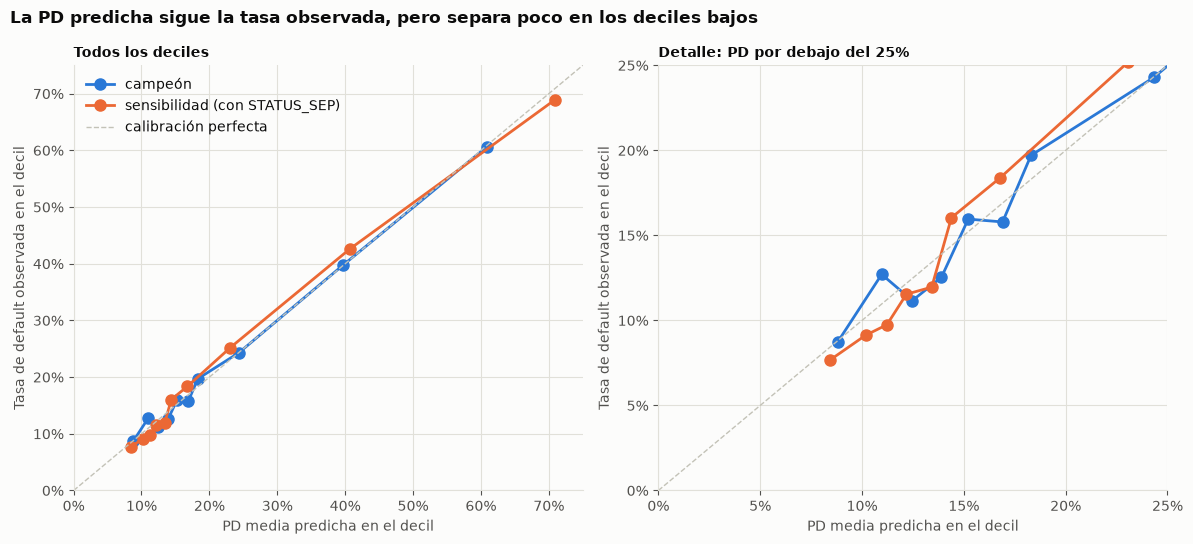

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))
limits = {0: 0.75, 1: 0.25}  # full range, and a zoom on the low-PD deciles
for k, ax in enumerate(axes):
    for name, model in report["models"].items():
        table = pd.DataFrame(model["cv"]["repeat_1"]["calibration_by_decile"])
        ax.plot(
            table["mean_pd"],
            table["default_rate"],
            marker="o",
            markersize=8,
            linewidth=2,
            color=colours[name],
            label=NAMES[name],
        )
    top = limits[k]
    ax.plot(
        [0, top],
        [0, top],
        color="#c3c2b7",
        linewidth=1,
        linestyle="--",
        label="calibración perfecta",
    )
    ax.set_xlim(0, top)
    ax.set_ylim(0, top)
    ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
    ax.yaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
    ax.set_xlabel("PD media predicha en el decil")
    ax.set_ylabel("Tasa de default observada en el decil")
axes[0].set_title("Todos los deciles", fontsize=10)
axes[1].set_title("Detalle: PD por debajo del 25%", fontsize=10)
axes[0].legend(loc="upper left")
fig.suptitle(
    "La PD predicha sigue la tasa observada, pero separa poco en los deciles bajos",
    x=0.01,
    ha="left",
    fontweight="bold",
)
fig.tight_layout()
plotting.save_figure(fig, "pd_reliability_cv")
plt.show()

En conjunto el campeón está bien calibrado: la PD media predicha coincide con la tasa observada,
la calibración global es prácticamente cero y la pendiente es 0.986, muy cerca de 1. Esto es lo
esperable: una logística con intercepto reproduce la tasa de su muestra de ajuste, y los folds están
estratificados. No se recalibra (ADR-012).

Pero el detalle por decil muestra un límite del modelo: **en los deciles bajos la tasa observada no
crece de forma ordenada**. En el campeón, el decil 2 tiene una tasa observada mayor que el decil 3,
y el 5 una apenas mayor que el 6; los siete deciles más bajos tienen PD entre 9% y 18%. El modelo
separa bien a las cuentas de mayor riesgo (los tres deciles superiores) y poco entre las de riesgo
bajo y medio. En cambio, el modelo de sensibilidad sí ordena todos sus deciles. Esto se reporta tal
como sale; no se cambia el modelo por ello.

## 6. Puntos de operación del campeón

Qué pasaría si se marcara para gestión a una parte de las cuentas: las de mayor PD (10%, 20% o
30% de la cartera) o todas las que superen un umbral de PD (la tasa promedio de train o 0.5). El
umbral definitivo se elige por costos en la fase de impacto de negocio; aquí solo se muestran
opciones, sobre las predicciones fuera de fold.

En la evaluación en test se reportarán las dos cosas: los umbrales de PD fijados aquí (incluidos
los que marcaron el 10%, 20% y 30% en validación cruzada) y la captura al marcar el 10%, 20% o 30%
de las cuentas de test con mayor PD, que es una regla de capacidad.

In [10]:
points = pd.DataFrame(report["models"]["champion"]["cv"]["repeat_1"]["operating_points"])
points["point"] = points["point"].str.replace("flag", "marcar").str.replace("PD >=", "PD ≥")
points_view = pd.DataFrame(
    {
        "umbral de PD": points["threshold"].round(3),
        "cuentas marcadas": points["flag_rate"].map("{:.1%}".format),
        "recall (defaults capturados)": points["recall"].map("{:.1%}".format),
        "precisión": points["precision"].map("{:.1%}".format),
        "falsos positivos": points["false_positive_rate"].map("{:.1%}".format),
    }
)
points_view.index = points["point"]
points_view.index.name = "punto"
display(points_view)

,umbral de PD,cuentas marcadas,recall (defaults capturados),precisión,falsos positivos
punto,,,,,
marcar 10%,0.498,10.0%,27.4%,60.6%,5.1%
marcar 20%,0.316,20.1%,45.5%,50.1%,12.9%
marcar 30%,0.199,30.0%,56.3%,41.5%,22.5%
PD ≥ 0.221208,0.221,25.5%,52.0%,45.0%,18.0%
PD ≥ 0.5,0.500,9.9%,27.1%,60.7%,5.0%


## 7. Limitaciones

- **Una sola foto.** Train y validación vienen de los mismos meses; nada de esto mide cómo se
  comportaría el modelo en otro período (ADR-003).
- **Los folds ya se usaron en la fase anterior** para excluir `AGE` y `EDUCATION`, así que las
  métricas de validación cruzada no son del todo independientes de esas decisiones (ADR-011). El
  efecto no está cuantificado; la estimación limpia será la del test.
- **Intervalos condicionados.** El intervalo bootstrap deja fijos los modelos de cada fold, y los
  errores estándar de los coeficientes no consideran que las variables y los bins se eligieron con
  los mismos datos; ambos son algo optimistas.
- **Ordenamiento en los deciles bajos.** La tasa observada no crece de forma ordenada entre los
  deciles 2 y 4 (y 5 y 6) del campeón.
- **Gemelos dentro de train.** 140 filas de train tienen un gemelo en las variables candidatas y
  pueden quedar en folds distintos (ADR-010), lo que favorece un poco las métricas.
- **La lista de variables no es única.** Los ratios de pago se reemplazan entre sí de un fold a
  otro; la lista del campeón es la que sale con todo train.
- **Calibración ligada a la tasa del archivo.** El 22% de default de este archivo no se puede leer
  como la tasa de la cartera del banco (`docs/DATA.md`); en otra población habría que recalibrar.
- **Supuestos de las variables.** Que los montos de septiembre y el historial de agosto a abril se
  conocieran antes de octubre es un SUPUESTO (ADR-009).

## 8. Guardado de resultados (entrenamiento)

Las cifras de este notebook y de ADR-012 salen de este archivo, que además **congela los modelos**:
la evaluación en test se niega a correr si las variables o los coeficientes no coinciden con los
guardados aquí. Esa evaluación se guardará aparte, en `reports/metrics/pd_logistic_test.json`.

In [11]:
# load_train() already checked the raw file against this hash.
data_sha256 = load_config("project")["data"]["raw_sha256"]
path = save_metrics("pd_logistic_cv", report, data_sha256)
print(f"Guardado en {path.relative_to(path.parents[2]).as_posix()}")

Guardado en reports/metrics/pd_logistic_cv.json


## 9. Evaluación final en test (una sola vez)

Con los dos modelos congelados en el archivo de la sección anterior, se evalúan en las 6,000 filas
de test que ninguna decisión ha visto. `evaluate_on_test` comprueba antes que los modelos coinciden
con los congelados, y guarda el resultado en `reports/metrics/pd_logistic_test.json`.

In [12]:
from creditrisk.models.final_evaluation import evaluate_on_test

test_report = evaluate_on_test(
    models, compare=("sensitivity_with_status_sep", "champion"), n_boot=1000
)
print(f"Filas de test: {test_report['n_test_rows']:,}")
print(f"Filas de test con gemelo en train: {test_report['n_test_rows_with_twin_in_train']}")

Filas de test: 6,000
Filas de test con gemelo en train: 43


In [13]:
SUBSETS = {"all_rows": "todas las filas", "without_twins": "sin gemelos en train"}
rows = {}
for name, by_subset in test_report["models"].items():
    for subset, label in SUBSETS.items():
        r = by_subset[subset]
        row = {"filas": f"{r['n_rows']:,}"}
        for metric, metric_label in [
            ("auc", "AUC"),
            ("gini", "Gini"),
            ("ks", "KS"),
            ("pr_auc", "PR-AUC"),
        ]:
            m = r[metric]
            row[metric_label] = f"{m['estimate']:.3f} [{m['low']:.3f}, {m['high']:.3f}]"
        rows[(NAMES[name], label)] = row
test_discrimination = pd.DataFrame(rows).T
test_discrimination.index.names = ["modelo", "filas evaluadas"]
display(test_discrimination)

diff = test_report["auc_difference"]
for subset, label in SUBSETS.items():
    d = diff[subset]
    print(
        f"Diferencia de AUC, sensibilidad menos campeón ({label}): "
        f"{d['estimate']:.3f} [{d['low']:.3f}, {d['high']:.3f}]"
    )

filas                   AUC                  Gini                    KS                PR-AUC
modelo                        filas evaluadas                                                                                                    
campeón                       todas las filas       6,000  0.719 [0.703, 0.736]  0.439 [0.405, 0.473]  0.359 [0.333, 0.390]  0.474 [0.449, 0.502]
                              sin gemelos en train  5,957  0.721 [0.705, 0.737]  0.442 [0.410, 0.474]  0.366 [0.339, 0.396]  0.475 [0.451, 0.501]
sensibilidad (con STATUS_SEP) todas las filas       6,000  0.764 [0.748, 0.779]  0.527 [0.497, 0.559]  0.428 [0.403, 0.458]  0.542 [0.516, 0.569]
                              sin gemelos en train  5,957  0.764 [0.748, 0.780]  0.528 [0.497, 0.560]  0.428 [0.403, 0.456]  0.541 [0.515, 0.568]

Diferencia de AUC, sensibilidad menos campeón (todas las filas): 0.044 [0.035, 0.054]
Diferencia de AUC, sensibilidad menos campeón (sin gemelos en train): 0.043 [0.033, 0.053]


In [14]:
rows = {}
for name, by_subset in test_report["models"].items():
    r = by_subset["all_rows"]
    rows[NAMES[name]] = {
        "PD media predicha": f"{r['mean_pd']:.2%}",
        "tasa observada": f"{r['default_rate']:.2%}",
        "Brier": f"{r['calibration']['brier']:.4f}",
        "calibración global": f"{r['calibration']['calibration_in_the_large']:.3f}",
        "pendiente de calibración": f"{r['calibration']['calibration_slope']:.3f}",
    }
test_calibration = pd.DataFrame(rows).T
test_calibration.index.name = "modelo (todas las filas)"
display(test_calibration)

test_deciles = pd.DataFrame(test_report["models"]["champion"]["all_rows"]["calibration_by_decile"])
print("Campeón en test, por decil de PD predicha")
display(
    test_deciles.rename(
        columns={
            "group": "decil",
            "n": "cuentas",
            "mean_pd": "PD media",
            "default_rate": "tasa observada",
        }
    )
    .set_index("decil")
    .round(3)
)

,PD media predicha,tasa observada,Brier,calibración global,pendiente de calibración
modelo (todas las filas),,,,,
campeón,21.76%,22.12%,0.1468,0.024,1.037
sensibilidad (con STATUS_SEP),22.02%,22.12%,0.1357,0.007,1.021


Campeón en test, por decil de PD predicha


,cuentas,PD media,tasa observada
decil,,,
1,600,0.088,0.095
2,600,0.109,0.120
3,600,0.124,0.110
4,600,0.138,0.142
5,600,0.151,0.162
6,600,0.168,0.130
7,600,0.181,0.172
8,600,0.237,0.270
9,600,0.379,0.390


In [15]:
points = pd.DataFrame(test_report["models"]["champion"]["all_rows"]["operating_points"])
points["point"] = (
    points["point"]
    .str.replace("flag", "capacidad: marcar")
    .str.replace("PD >=", "umbral fijo: PD ≥")
)
test_points = pd.DataFrame(
    {
        "umbral de PD": points["threshold"].round(3),
        "cuentas marcadas": points["flag_rate"].map("{:.1%}".format),
        "recall (defaults capturados)": points["recall"].map("{:.1%}".format),
        "precisión": points["precision"].map("{:.1%}".format),
    }
)
test_points.index = points["point"]
test_points.index.name = "punto (campeón, test)"
display(test_points)

,umbral de PD,cuentas marcadas,recall (defaults capturados),precisión
"punto (campeón, test)",,,,
capacidad: marcar 10%,0.481,10.0%,28.1%,62.2%
capacidad: marcar 20%,0.303,20.4%,46.3%,50.2%
capacidad: marcar 30%,0.197,30.0%,58.0%,42.7%
umbral fijo: PD ≥ 0.221208,0.221,25.3%,51.9%,45.4%
umbral fijo: PD ≥ 0.5,0.500,9.6%,27.3%,63.2%
umbral fijo: PD ≥ 0.497766,0.498,9.6%,27.5%,63.1%
umbral fijo: PD ≥ 0.316212,0.316,18.9%,44.4%,52.1%
umbral fijo: PD ≥ 0.198746,0.199,29.1%,56.9%,43.2%


**Lectura de los resultados en test.**

- **El AUC del campeón en test es compatible con el de validación cruzada:** 0.719 (IC 95% 0.703 a
  0.736) frente a 0.718 fuera de fold (0.710 a 0.725). No se detecta optimismo, aunque un solo test
  no permite descartar uno menor que su propia incertidumbre (unos ±0.017). KS 0.359 (0.333 a
  0.390) y PR-AUC 0.474 (0.449 a 0.502).
- **No se observa que los gemelos inflen el resultado:** sin las 43 filas con gemelo en train, el
  AUC es 0.721 (0.705 a 0.737).
- **Calibración:** la PD media predicha es 21.8% frente a una tasa observada de 22.1%; la calibración
  global es 0.024 (las PD son, en promedio, apenas bajas) y la pendiente 1.037, cerca de 1.
- **El ordenamiento en los deciles bajos y medios se confirma como limitación:** también en test la
  tasa observada no crece de forma ordenada; el decil 3 queda por debajo del 2, y el 6 por debajo
  del 4 y del 5 (13.0% frente a 14.2% y 16.2%). Los siete deciles inferiores tienen tasas observadas
  entre 9.5% y 17.2%, frente a 27.0%, 39.0% y 62.2% en los tres superiores: la discriminación del
  campeón está concentrada en esos tres deciles.
- **Puntos de operación:** marcar el 20% de cuentas con mayor PD (20.4% por empates en el umbral)
  captura el 46.3% de los defaults con una precisión del 50.2%. El umbral fijo que marcó el 20% en
  validación cruzada (PD ≥ 0.316) marca en test el 18.9% de las cuentas y captura el 44.4% de los
  defaults.
- **Modelo de sensibilidad:** AUC 0.764 (0.748 a 0.779). La diferencia con el campeón es 0.044 (IC
  95% pareado 0.035 a 0.054), y 0.043 sin gemelos (0.033 a 0.053): el intervalo excluye el cero en
  ambos casos. Si el estado de septiembre fuera legítimo, ese sería el costo de excluirlo; si no lo
  es, no es un costo.

**Nada cambia por estos resultados.** El campeón sigue siendo el modelo sin el estado de septiembre
(ADR-009), y ninguna decisión se revisa después de ver el test.

## Resumen

| Tema | Resultado | Fuente |
|---|---|---|
| Variables del campeón | 5, todas con el signo esperado y p < 0.01 | `pd_logistic_cv.json` |
| AUC del campeón | 0.718 (0.710 a 0.725) fuera de fold; 0.719 (0.703 a 0.736) en test | `pd_logistic_cv.json`, `pd_logistic_test.json` |
| Calibración del campeón | En test, PD media 21.8% frente a 22.1% observada y pendiente 1.04; ordenamiento imperfecto en los deciles bajos y medios | ambos |
| Modelo con el estado de septiembre | AUC 0.764 (0.748 a 0.779) en test; diferencia con el campeón 0.044 (IC pareado 0.035 a 0.054) | `pd_logistic_test.json` |
| Decisión | El campeón no usa el estado de septiembre (ADR-009) | ADR-012 |